# Практическая работа № 9
## Методы оценки плотности для выявления аномалий в кибербезопасности

Решение выполнено на `cyber_density_anomalies.csv` по материалам задания и лекции. Запускайте ячейки сверху вниз: следующие ячейки используют результаты предыдущих. Комментарии в коде объясняют действия и смысл промежуточных переменных; интерпретация результатов вынесена в текстовые ячейки.

`scenario` и `is_attack` — учебные метки для оценки качества. Они не участвуют в масштабировании, обучении моделей или выборе порогов. Поле `traffic_type` используется только для стратификации нормальной выборки и проверки состава групп.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KernelDensity
from sklearn.preprocessing import StandardScaler

# В числовых таблицах показываем больше столбцов, чтобы видеть весь результат.
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

In [2]:
# Эти три числовых признака передадим всем моделям.
# Идентификатор сессии и учебные метки не могут быть входными признаками.
FEATURES = ['connections_per_min', 'unique_destinations', 'outbound_mb']

# Файл CSV должен находиться в той же папке, что и блокнот.
data_path = Path('cyber_density_anomalies.csv')
if not data_path.exists():
    raise FileNotFoundError('Положите cyber_density_anomalies.csv рядом с блокнотом')

df = pd.read_csv(data_path)

# reference_normal — подтверждённая норма для построения профиля.
# monitoring — новые сессии, среди которых могут быть атаки.
reference_df = df.loc[df['dataset_part'] == 'reference_normal'].copy()
monitoring_df = df.loc[df['dataset_part'] == 'monitoring'].copy()


def quality_row(method_name, mode_name, threshold, prediction):
    # Сверяем готовые предсказания с учебной меткой только после работы модели.
    # Порядок labels=[0, 1] даёт матрицу [[TN, FP], [FN, TP]].
    true_labels = monitoring_df['is_attack']
    tn, fp, fn, tp = confusion_matrix(
        true_labels, prediction, labels=[0, 1]
    ).ravel()
    return {'Метод': method_name, 'Режим': mode_name,
            'Порог': threshold, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}


def detected_by_scenario(prediction):
    # Показываем, сколько атак каждого сценария метод обнаружил.
    attacks = monitoring_df.loc[monitoring_df['is_attack'] == 1,
                                ['scenario']].copy()
    attacks['Обнаружено'] = np.asarray(prediction)[
        monitoring_df['is_attack'].to_numpy() == 1
    ]
    return attacks.groupby('scenario')['Обнаружено'].agg(['sum', 'count'])


def fit_hbos(X, bins=12, alpha=1.0):
    # Для каждого признака строим отдельную гистограмму.
    # Модель хранит границы интервалов и сглаженные доли объектов в них.
    models = []
    n_objects = len(X)
    for feature_index in range(X.shape[1]):
        counts, edges = np.histogram(X[:, feature_index], bins=bins)

        # alpha добавляется к каждому интервалу, чтобы его вероятность
        # не оказалась нулевой даже при отсутствии обучающих объектов.
        probabilities = (counts + alpha) / (n_objects + alpha * bins)
        models.append({'edges': edges, 'probabilities': probabilities})
    return models


def hbos_score_samples(models, X, epsilon=1e-12):
    # Чем меньше вероятность интервала, тем больше -log(вероятность).
    # Сумма по трём признакам служит оценкой аномальности сессии.
    scores = np.zeros(len(X))
    for feature_index, model in enumerate(models):
        edges = model['edges']
        probabilities = model['probabilities']
        values = X[:, feature_index]

        # Находим номер интервала для каждого значения признака.
        bin_indices = np.searchsorted(edges, values, side='right') - 1
        bin_indices[values == edges[-1]] = len(probabilities) - 1
        inside = (bin_indices >= 0) & (bin_indices < len(probabilities))

        # Для значения за пределами обучающей гистограммы берём
        # очень малую положительную вероятность epsilon.
        point_probabilities = np.full(len(X), epsilon)
        point_probabilities[inside] = probabilities[bin_indices[inside]]
        scores -= np.log(point_probabilities)
    return scores

## Задание 1. Подготовка данных и режимов работы — 3 балла
1. Выполните аудит структуры, пропусков и дубликатов.
2. Подтвердите состав `reference_normal` и `monitoring`.
3. Подготовьте стандартизованную смешанную выборку.
4. Разделите подтверждённую норму на 75% fit и 25% calibration со стратификацией по `traffic_type`.
5. Объясните, почему scaler в режиме профиля нормы обучается только на `normal_fit_df`.

In [3]:
# Проверяем размер, типы данных, пропуски и полные дубликаты.
print('Размер всей таблицы:', df.shape)
print('Типы столбцов:')
display(df.dtypes.to_frame('Тип'))
print('Пропуски по столбцам:')
display(df.isna().sum().to_frame('Пропусков'))
print('Полных дубликатов:', int(df.duplicated().sum()))

# Считаем, какие записи попали в каждую часть набора.
print('Состав частей набора:')
display(pd.crosstab(df['dataset_part'], df['scenario']))
print('Типы трафика в частях набора:')
display(pd.crosstab(df['dataset_part'], df['traffic_type']))

# Смешанный режим: scaler видит только мониторинговую выборку целиком.
# Модель в этом режиме учится на тех же данных без доступа к меткам.
unsupervised_scaler = StandardScaler()
X_unsupervised = unsupervised_scaler.fit_transform(monitoring_df[FEATURES])

# От подтверждённой нормы отделяем 25% для независимой калибровки порога.
# stratify сохраняет доли web, api и backup в обеих частях.
normal_fit_df, normal_calibration_df = train_test_split(
    reference_df, test_size=0.25, random_state=42,
    stratify=reference_df['traffic_type']
)

# В режиме профиля нормы среднее и разброс scaler вычисляются только
# по normal_fit_df. Калибровка и мониторинг преобразуются тем же scaler.
normal_scaler = StandardScaler()
X_normal_fit = normal_scaler.fit_transform(normal_fit_df[FEATURES])
X_normal_calibration = normal_scaler.transform(
    normal_calibration_df[FEATURES]
)
X_monitoring = normal_scaler.transform(monitoring_df[FEATURES])

print('Размеры: профиль нормы', len(reference_df),
      '| fit', len(normal_fit_df),
      '| calibration', len(normal_calibration_df),
      '| monitoring', len(monitoring_df))
print('Типы трафика после разделения нормы:')
display(pd.DataFrame({
    'fit': normal_fit_df['traffic_type'].value_counts(),
    'calibration': normal_calibration_df['traffic_type'].value_counts()
}).fillna(0).astype(int))

Размер всей таблицы: (854, 8)
Типы столбцов:


,Тип
session_id,object
connections_per_min,float64
unique_destinations,float64
outbound_mb,float64
traffic_type,object
scenario,object
is_attack,int64
dataset_part,object


Пропуски по столбцам:


,Пропусков
session_id,0
connections_per_min,0
unique_destinations,0
outbound_mb,0
traffic_type,0
scenario,0
is_attack,0
dataset_part,0


Полных дубликатов: 0
Состав частей набора:


scenario,beaconing,exfiltration,lateral_movement,normal,port_scan
dataset_part,,,,,
monitoring,4,3,3,240,4
reference_normal,0,0,0,600,0


Типы трафика в частях набора:


traffic_type,api,backup,unknown,web
dataset_part,,,,
monitoring,72,24,14,144
reference_normal,180,60,0,360


Размеры: профиль нормы 600 | fit 450 | calibration 150 | monitoring 254
Типы трафика после разделения нормы:


,fit,calibration
traffic_type,,
web,270,90
api,135,45
backup,45,15


### Вывод по заданию 1

В таблице 854 сессии и 8 исходных столбцов; пропусков и полных дубликатов нет. `reference_normal` содержит 600 нормальных сессий, а `monitoring` — 240 нормальных и 14 атакующих. Подтверждённая норма разделена на 450 обучающих и 150 калибровочных строк: в каждой сохранены доли web, api и backup. Смешанная выборка стандартизуется по всем 254 строкам мониторинга; при построении профиля нормы `StandardScaler` обучается только на 450 нормальных строках. Иначе атаки или калибровочные данные повлияли бы на среднее и стандартное отклонение признаков ещё до проверки модели. Метки `scenario` и `is_attack` используются только после получения предсказаний.

## Задание 2. KDE в двух режимах — 5 баллов
Используйте гауссовское ядро и `bandwidth=0.35`. Рассчитайте score как отрицательный логарифм плотности. Для смешанной выборки примените квантиль `1 − 0.055`; для профиля нормы — 99-й процентиль калибровочных нормальных оценок. Выведите пороги, TP, FP, FN, TN и обнаружение по сценариям.

In [4]:
# Один список будет собирать качество всех шести вариантов.
results = []

# Режим 1: KDE строит плотность по смешанной мониторинговой выборке.
# score_samples возвращает log(плотность); знак минус делает редкие
# объекты объектами с БОЛЬШИМ score.
kde_mixed = KernelDensity(kernel='gaussian', bandwidth=0.35)
kde_mixed.fit(X_unsupervised)
kde_mixed_scores = -kde_mixed.score_samples(X_unsupervised)

# Предполагаем, что 5,5% объектов могут быть аномальными.
# Порог — 94,5-й процентиль оценок на той же смешанной выборке.
kde_mixed_threshold = np.quantile(kde_mixed_scores, 1 - 0.055)
kde_mixed_prediction = (kde_mixed_scores > kde_mixed_threshold).astype(int)
results.append(quality_row('KDE', 'Смешанный',
                           kde_mixed_threshold, kde_mixed_prediction))

# Режим 2: модель видит только нормальную обучающую часть.
kde_normal = KernelDensity(kernel='gaussian', bandwidth=0.35)
kde_normal.fit(X_normal_fit)

# Калибровка не участвовала в обучении: её 99-й процентиль
# задаёт порог для новых событий в масштабе профиля нормы.
kde_calibration_scores = -kde_normal.score_samples(X_normal_calibration)
kde_normal_threshold = np.quantile(kde_calibration_scores, 0.99)
kde_normal_scores = -kde_normal.score_samples(X_monitoring)
kde_normal_prediction = (kde_normal_scores > kde_normal_threshold).astype(int)
results.append(quality_row('KDE', 'Профиль нормы',
                           kde_normal_threshold, kde_normal_prediction))

display(pd.DataFrame(results).round({'Порог': 4}))
print('Обнаружение атак по сценариям, смешанный режим:')
display(detected_by_scenario(kde_mixed_prediction))
print('Обнаружение атак по сценариям, профиль нормы:')
display(detected_by_scenario(kde_normal_prediction))

,Метод,Режим,Порог,TP,FP,FN,TN
0,KDE,Смешанный,2.6596,11,3,3,237
1,KDE,Профиль нормы,3.8019,14,1,0,239


Обнаружение атак по сценариям, смешанный режим:


,sum,count
scenario,,
beaconing,1,4
exfiltration,3,3
lateral_movement,3,3
port_scan,4,4


Обнаружение атак по сценариям, профиль нормы:


,sum,count
scenario,,
beaconing,4,4
exfiltration,3,3
lateral_movement,3,3
port_scan,4,4


### Вывод по заданию 2

В смешанном режиме KDE при пороге 2,6596 обнаружил 11 из 14 атак (TP=11), дал 3 ложные тревоги (FP=3), пропустил 3 атаки (FN=3) и правильно распознал 237 нормальных сессий (TN=237). Все три пропуска относятся к `beaconing`: этот сценарий частично попал в плотность смешанной обучающей выборки. Профиль нормы при пороге 3,8019 обнаружил все 14 атак, дал 1 ложную тревогу и не пропустил ни одной атаки. Здесь порог рассчитан по 99-му процентилю отложенных нормальных оценок, поэтому атаки не участвовали ни в обучении плотности, ни в настройке порога. Значение `-log(плотность)` выражает редкость события относительно модели, а не вероятность атаки.

## Задание 3. GMM в двух режимах — 4 балла
Используйте три компоненты, полные ковариационные матрицы, `reg_covar=1e-6`, `random_state=42`, `n_init=1`. Рассчитайте `−log p(x)`, выберите пороги по тем же правилам и сопоставьте два режима.

In [5]:
# У обеих GMM три компоненты с полными ковариационными матрицами.
# random_state нужен, чтобы при повторном запуске получить тот же результат.
gmm_options = {'n_components': 3, 'covariance_type': 'full',
               'reg_covar': 1e-6, 'random_state': 42, 'n_init': 1}

# Режим 1: обучаем GMM на смешанных данных.
gmm_mixed = GaussianMixture(**gmm_options)
gmm_mixed.fit(X_unsupervised)
gmm_mixed_scores = -gmm_mixed.score_samples(X_unsupervised)
gmm_mixed_threshold = np.quantile(gmm_mixed_scores, 1 - 0.055)
gmm_mixed_prediction = (gmm_mixed_scores > gmm_mixed_threshold).astype(int)
results.append(quality_row('GMM', 'Смешанный',
                           gmm_mixed_threshold, gmm_mixed_prediction))

# Режим 2: параметры трёх компонент получаем только из нормального fit.
# Порог задаём по отложенным нормальным событиям, а не по атакам.
gmm_normal = GaussianMixture(**gmm_options)
gmm_normal.fit(X_normal_fit)
gmm_calibration_scores = -gmm_normal.score_samples(X_normal_calibration)
gmm_normal_threshold = np.quantile(gmm_calibration_scores, 0.99)
gmm_normal_scores = -gmm_normal.score_samples(X_monitoring)
gmm_normal_prediction = (gmm_normal_scores > gmm_normal_threshold).astype(int)
results.append(quality_row('GMM', 'Профиль нормы',
                           gmm_normal_threshold, gmm_normal_prediction))

display(pd.DataFrame(results[-2:]).round({'Порог': 4}))
print('Обнаружение атак по сценариям, смешанный режим:')
display(detected_by_scenario(gmm_mixed_prediction))
print('Обнаружение атак по сценариям, профиль нормы:')
display(detected_by_scenario(gmm_normal_prediction))

,Метод,Режим,Порог,TP,FP,FN,TN
0,GMM,Смешанный,3.0883,10,4,4,236
1,GMM,Профиль нормы,4.8702,14,1,0,239


Обнаружение атак по сценариям, смешанный режим:


,sum,count
scenario,,
beaconing,4,4
exfiltration,3,3
lateral_movement,3,3
port_scan,0,4


Обнаружение атак по сценариям, профиль нормы:


,sum,count
scenario,,
beaconing,4,4
exfiltration,3,3
lateral_movement,3,3
port_scan,4,4


### Вывод по заданию 3

Смешанная GMM при пороге 3,0883 обнаружила 10 атак, дала 4 ложные тревоги и пропустила все четыре сессии `port_scan`; 236 нормальных событий распознаны верно. При обучении только на норме и калибровочном пороге 4,8702 модель обнаружила все 14 атак при одной ложной тревоге. В смешанном режиме три гауссовых компоненты могут описать и плотную группу атакующих событий, из-за чего эта группа перестаёт быть редкой для модели. Полные ковариационные матрицы позволяют GMM учитывать совместное поведение признаков внутри компонентов. Эти результаты относятся к конкретному набору и выбранным параметрам модели.

## Задание 4. HBOS в двух режимах — 4 балла
Используйте ручные функции лекции, 12 интервалов и сглаживание `alpha=1.0`. В смешанном режиме задайте долю 0.05; в режиме профиля нормы примените 99-й процентиль калибровочных оценок. Установите, какие атаки пропущены, и объясните результат через предположение независимости признаков.

In [6]:
# HBOS строит для каждого признака отдельную гистограмму.
# Используем 12 интервалов и сглаживание 1.0, как требует задание.
hbos_mixed = fit_hbos(X_unsupervised, bins=12, alpha=1.0)
hbos_mixed_scores = hbos_score_samples(hbos_mixed, X_unsupervised)

# В смешанном режиме допускаем 5% аномалий: порог = 95-й процентиль.
hbos_mixed_threshold = np.quantile(hbos_mixed_scores, 1 - 0.05)
hbos_mixed_prediction = (hbos_mixed_scores > hbos_mixed_threshold).astype(int)
results.append(quality_row('HBOS', 'Смешанный',
                           hbos_mixed_threshold, hbos_mixed_prediction))

# Для профиля нормы гистограммы строятся только по normal_fit_df.
# Порог опять определяют только отложенные нормальные сессии.
hbos_normal = fit_hbos(X_normal_fit, bins=12, alpha=1.0)
hbos_calibration_scores = hbos_score_samples(hbos_normal,
                                             X_normal_calibration)
hbos_normal_threshold = np.quantile(hbos_calibration_scores, 0.99)
hbos_normal_scores = hbos_score_samples(hbos_normal, X_monitoring)
hbos_normal_prediction = (hbos_normal_scores > hbos_normal_threshold).astype(int)
results.append(quality_row('HBOS', 'Профиль нормы',
                           hbos_normal_threshold, hbos_normal_prediction))

display(pd.DataFrame(results[-2:]).round({'Порог': 4}))
print('Обнаружение атак по сценариям, смешанный режим:')
display(detected_by_scenario(hbos_mixed_prediction))
print('Обнаружение атак по сценариям, профиль нормы:')
display(detected_by_scenario(hbos_normal_prediction))

# Показываем именно те атакующие сессии, которые каждый режим пропустил.
attack_columns = ['session_id', 'scenario', *FEATURES]
attack_mask = monitoring_df['is_attack'] == 1
print('Пропущены HBOS в смешанном режиме:')
display(monitoring_df.loc[attack_mask & (hbos_mixed_prediction == 0),
                          attack_columns])
print('Пропущены HBOS в режиме профиля нормы:')
display(monitoring_df.loc[attack_mask & (hbos_normal_prediction == 0),
                          attack_columns])

,Метод,Режим,Порог,TP,FP,FN,TN
0,HBOS,Смешанный,6.0857,8,1,6,239
1,HBOS,Профиль нормы,10.6194,10,3,4,237


Обнаружение атак по сценариям, смешанный режим:


,sum,count
scenario,,
beaconing,0,4
exfiltration,1,3
lateral_movement,3,3
port_scan,4,4


Обнаружение атак по сценариям, профиль нормы:


,sum,count
scenario,,
beaconing,0,4
exfiltration,3,3
lateral_movement,3,3
port_scan,4,4


Пропущены HBOS в смешанном режиме:


,session_id,scenario,connections_per_min,unique_destinations,outbound_mb
844,S0844,exfiltration,55.73,13.29,644.75
846,S0846,exfiltration,56.84,14.26,664.41
847,S0847,beaconing,76.22,0.94,3.39
848,S0848,beaconing,74.86,0.90,2.84
849,S0849,beaconing,81.06,0.65,3.25
850,S0850,beaconing,69.96,0.98,2.78


Пропущены HBOS в режиме профиля нормы:


,session_id,scenario,connections_per_min,unique_destinations,outbound_mb
847,S0847,beaconing,76.22,0.94,3.39
848,S0848,beaconing,74.86,0.90,2.84
849,S0849,beaconing,81.06,0.65,3.25
850,S0850,beaconing,69.96,0.98,2.78


### Вывод по заданию 4

Смешанный HBOS при пороге 6,0857 обнаружил 8 атак и дал 1 ложную тревогу; он пропустил две сессии `exfiltration` (S0844 и S0846) и все четыре `beaconing`. При профиле нормы порог 10,6194 дал 10 обнаруженных атак и 3 ложные тревоги, но все четыре `beaconing` остались пропущенными. HBOS суммирует оценки отдельных признаков по гистограммам и не моделирует их связи: сочетание значений может быть редким, даже если каждое значение само по себе встречается в нормальном трафике. В смешанном режиме атаки дополнительно влияют на ширину и заполнение интервалов гистограмм. Размер и число интервалов могут изменить результат, поэтому вывод о качестве HBOS нельзя переносить на другие данные без проверки.

## Задание 5. Сравнение методов и вывод SOC — 4 балла
Сведите TP, FP, FN, TN для шести комбинаций метода и режима в одну таблицу, постройте показанные в лекции гистограммы KDE-оценок с порогами и подготовьте аналитическую записку SOC из 5–7 предложений. Укажите набор данных, методы, пороги, результаты, ограничения и рекомендуемую проверку.

,Метод,Режим,Порог,TP,FP,FN,TN
0,KDE,Смешанный,2.6596,11,3,3,237
1,KDE,Профиль нормы,3.8019,14,1,0,239
2,GMM,Смешанный,3.0883,10,4,4,236
3,GMM,Профиль нормы,4.8702,14,1,0,239
4,HBOS,Смешанный,6.0857,8,1,6,239
5,HBOS,Профиль нормы,10.6194,10,3,4,237


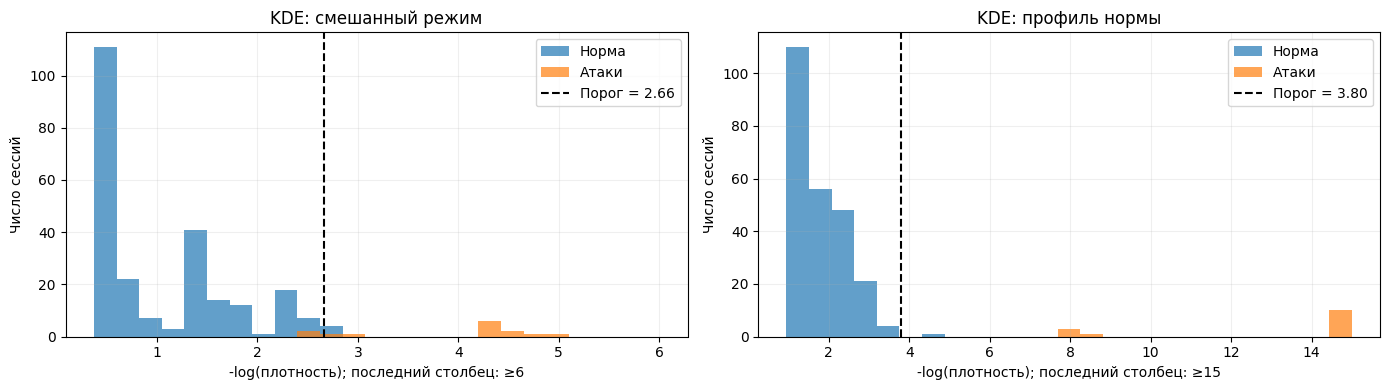

In [7]:
# Одна строка таблицы — один метод в одном режиме.
# TP/FP/FN/TN рассчитаны на одних и тех же 254 сессиях мониторинга.
comparison = pd.DataFrame(results)
display(comparison.round({'Порог': 4}))

# Для KDE строим две гистограммы оценок на мониторинговых данных.
# Синие столбцы — нормальные сессии, красные — атаки по учебной метке.
# Метка нужна только для отображения и не влияла на расчёт KDE и порога.
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
normal_mask = monitoring_df['is_attack'].to_numpy() == 0
attack_mask = ~normal_mask

for ax, scores, threshold, title, plot_limit in [
    (axes[0], kde_mixed_scores, kde_mixed_threshold, 'KDE: смешанный режим', 6),
    (axes[1], kde_normal_scores, kde_normal_threshold, 'KDE: профиль нормы', 15)
]:
    # Очень большие оценки профиля нормы растягивают ось до тысяч.
    # Только на рисунке объединяем все значения выше plot_limit
    # в последний столбец; расчёты выше выполнены по исходным score.
    shown_scores = np.minimum(scores, plot_limit)
    bins = np.linspace(shown_scores.min(), plot_limit, 26)
    ax.hist(shown_scores[normal_mask], bins=bins, alpha=0.7, label='Норма')
    ax.hist(shown_scores[attack_mask], bins=bins, alpha=0.7, label='Атаки')
    ax.axvline(threshold, color='black', linestyle='--',
               label=f'Порог = {threshold:.2f}')
    ax.set_title(title)
    ax.set_xlabel(f'-log(плотность); последний столбец: ≥{plot_limit}')
    ax.set_ylabel('Число сессий')
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Аналитическая записка SOC

Набор включает 600 подтверждённо нормальных сессий для построения профиля и 254 сессии мониторинга, среди которых учебная разметка указывает 14 атак. Методы KDE, GMM и HBOS применены в смешанном режиме с порогами соответственно 2,6596, 3,0883 и 6,0857, а также в режиме профиля нормы с порогами 3,8019, 4,8702 и 10,6194. В смешанном режиме обнаружено соответственно 11, 10 и 8 атак при 3, 4 и 1 ложной тревоге; KDE и GMM с профилем нормы обнаружили все 14 атак при одной ложной тревоге каждый. HBOS с профилем нормы обнаружил 10 атак при трёх ложных тревогах и пропустил четыре сессии `beaconing` (S0847–S0850), поэтому для этого сценария полезно оценивать сочетание признаков методом KDE или GMM. Сессии `port_scan` (S0840–S0843), `exfiltration` (S0844–S0846) и `lateral_movement` (S0851–S0853) требуют проверки сетевых журналов, адресов назначения, объёмов передачи и контекста пользователей; статистический сигнал сам по себе не доказывает атаку. Смешанные модели могут включать атаки в свой профиль, а частота ложных тревог зависит от выбранных квантилей и изменения трафика, поэтому пороги следует проверять на новых данных и пересматривать при изменении нормального поведения.